# 01 - Preprocessing Dataset

Notebook ini mengubah dataset komentar YouTube berlabel dari **raw** menjadi **clean**, siap dipakai untuk training.
Data tidak di-scraping di sini karena dataset Kaggle `yaemico/judionline` sudah memiliki label.

**Alur:** dataset raw -> cleaning teks -> filter panjang -> buang konflik label -> buang duplikat -> CSV clean

| | |
|---|---|
| **Cara menjalankan** | `Run All`, tidak ada yang perlu diubah |
| **Input** | dataset Kaggle `yaemico/judionline` (versi 3) dan `data/youtubeemoji.csv` |
| **Output utama** | `data/dataset_clean.csv` (kolomnya sama dengan dataset raw) |
| **Untuk laporan** | Tabel 1.1 - 1.7 dan Gambar 1.1 - 1.2; file tersimpan di `outputs/` |

## 1. Setup

In [1]:
%pip install -q kagglehub emoji nltk pandas jinja2 matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob
import os
import re
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

import emoji
import kagglehub
import matplotlib.pyplot as plt
import nltk
import pandas as pd
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
pd.set_option("display.max_colwidth", 90)
os.makedirs("outputs", exist_ok=True)

WARNA_LABEL = {0: "#2a78d6", 1: "#eb6834"}   # biru = normal, oranye = promosi judi
NAMA_LABEL = {0: "Normal (0)", 1: "Promosi judi (1)"}
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})


def tampil(tabel, judul, file=None, sembunyikan_index=False):
    """Menampilkan tabel yang rapi untuk di-screenshot. Jika file diisi, tabel juga disimpan ke outputs/."""
    if file:
        tabel.to_csv(f"outputs/{file}", index=not sembunyikan_index)
    gaya = (tabel.style.set_caption(judul).format(precision=4, na_rep="-")
            .set_properties(**{"text-align": "left", "white-space": "normal"})
            .set_table_styles([
                {"selector": "caption", "props": "caption-side: top; font-weight: bold; font-size: 1.05em; "
                                                 "text-align: left; padding-bottom: 6px; color: inherit;"},
                {"selector": "th", "props": "text-align: left;"},
            ]))
    display(gaya.hide(axis="index") if sembunyikan_index else gaya)

## 2. Memuat dataset raw

In [3]:
path = kagglehub.dataset_download("yaemico/judionline/versions/3")
df_raw = pd.read_csv(glob.glob(os.path.join(path, "*.csv"))[0])
print(f"{df_raw.shape[0]:,} baris, {df_raw.shape[1]} kolom")

10,230 baris, 9 kolom


**Tabel 1.1. Kolom dataset**

| Kolom | Isi | Dipakai model? |
|---|---|---|
| `video_id`, `title`, `channel_name` | identitas video | tidak |
| `tanggal` | waktu komentar (format bawaan dataset tidak seragam) | tidak |
| `author` | nama pengguna penulis komentar | tidak |
| `komentar` | **teks asli komentar**, sumber cleaning | sumber |
| `label` | **label kebenaran**: 0 = normal, 1 = promosi judi | **target** |
| `komentar_clean` | teks bersih; isinya akan **dibuat ulang** di notebook ini | **input** |
| `predicted_label` | kolom bawaan dataset; hanya disimpan agar format CSV tetap sama | tidak |

In [4]:
distribusi = pd.DataFrame({"Jumlah": df_raw["label"].value_counts(),
                           "Persen (%)": df_raw["label"].value_counts(normalize=True).mul(100).round(1)})
tampil(distribusi.rename(index=NAMA_LABEL).rename_axis("Label"), "Tabel 1.2. Distribusi label dataset raw")

,Jumlah,Persen (%)
Label,,
Normal (0),6021,58.9000
Promosi judi (1),4209,41.1000


## 3. Fungsi cleaning

| Urutan | Langkah | Tujuan |
|---|---|---|
| 1 | hapus emoji, huruf bendera, dan emoji khusus YouTube (`:hand-pink-waving:`) | hanya teks yang dianalisis |
| 2 | ubah ke huruf kecil | `Gacor` dan `gacor` menjadi kata yang sama |
| 3 | hapus URL, mention `@nama`, dan hashtag `#tag` | membuang bagian yang unik per komentar |
| 4 | rapikan baris baru dan spasi | format teks seragam |
| 5 | tokenisasi NLTK | memecah kalimat menjadi kata dan tanda baca |
| 6 | hapus stopword bahasa Indonesia (`yang`, `di`, `dan`, ...) | membuang kata umum |

Fungsi yang **sama persis** dipakai lagi di notebook 03, karena model harus menerima teks dengan bentuk yang sama saat
training dan saat prediksi.

In [5]:
yt_emoji_list = pd.read_csv("data/youtubeemoji.csv")["Emoji label"].tolist()
yt_emoji_pattern = re.compile("|".join(re.escape(e) for e in yt_emoji_list))
stop_words = set(stopwords.words("indonesian"))
HURUF_BENDERA = {chr(c) for c in range(0x1F1E6, 0x1F200)}   # 26 huruf penyusun emoji bendera


def remove_flags(text):
    return "".join(c for c in text if c not in HURUF_BENDERA)


def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    text = emoji.replace_emoji(text, replace="")             # hapus emoji
    text = remove_flags(text)                                # hapus huruf bendera
    text = yt_emoji_pattern.sub("", text)                    # hapus emoji khusus YouTube
    text = text.lower()                                      # huruf kecil
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)     # hapus URL
    text = re.sub(r"@\w+|\#\w+", "", text)                   # hapus mention dan hashtag
    text = re.sub(r"\n", " ", text)                          # ganti baris baru dengan spasi
    text = re.sub(r"\s+", " ", text).strip()                 # rapikan spasi
    tokens = word_tokenize(text)                             # pecah menjadi token
    tokens = [w for w in tokens if w not in stop_words]      # hapus stopword Indonesia
    return " ".join(tokens)

### Contoh per langkah

Tabel berikut memakai satu **kalimat buatan** agar setiap langkah terlihat jelas.

In [6]:
teks = "Yuk MAIN di Alexis17 😍 sekarang juga!\nInfo: https://contoh.com @budi #gacor"
langkah = [("Teks asli", teks)]

t = yt_emoji_pattern.sub("", remove_flags(emoji.replace_emoji(teks, replace="")))
langkah.append(("1. Hapus emoji", t))
t = t.lower()
langkah.append(("2. Huruf kecil", t))
t = re.sub(r"@\w+|\#\w+", "", re.sub(r"http\S+|www\S+|https\S+", "", t))
langkah.append(("3. Hapus URL, mention, hashtag", t))
t = re.sub(r"\s+", " ", re.sub(r"\n", " ", t)).strip()
langkah.append(("4. Rapikan spasi", t))
token = word_tokenize(t)
langkah.append(("5. Tokenisasi", str(token)))
token = [w for w in token if w not in stop_words]
langkah.append(("6. Hapus stopword", " ".join(token)))
assert " ".join(token) == clean_text(teks)   # memastikan hasilnya sama dengan fungsi clean_text

tampil(pd.DataFrame(langkah, columns=["Langkah", "Hasil"]), "Tabel 1.3. Contoh cleaning per langkah", sembunyikan_index=True)

Langkah,Hasil
Teks asli,Yuk MAIN di Alexis17 😍 sekarang juga! Info: https://contoh.com @budi #gacor
1. Hapus emoji,Yuk MAIN di Alexis17 sekarang juga! Info: https://contoh.com @budi #gacor
2. Huruf kecil,yuk main di alexis17 sekarang juga! info: https://contoh.com @budi #gacor
"3. Hapus URL, mention, hashtag",yuk main di alexis17 sekarang juga! info:
4. Rapikan spasi,yuk main di alexis17 sekarang juga! info:
5. Tokenisasi,"['yuk', 'main', 'di', 'alexis17', 'sekarang', 'juga', '!', 'info', ':']"
6. Hapus stopword,yuk main alexis17 ! info :


**Batasan:** huruf bergaya seperti `𝐒𝐆𝐈𝟖𝟖` tidak diubah menjadi huruf biasa. Bagi model, token tersebut
berbeda dari `sgi88`. Contohnya terlihat pada Tabel 1.4.

## 4. Menerapkan cleaning

In [7]:
df = df_raw.copy()
df["komentar_clean"] = df["komentar"].apply(clean_text)
df["panjang"] = df["komentar_clean"].str.len()
tahapan = {"Raw": df["label"].value_counts()}

contoh = df[["komentar", "komentar_clean", "label"]].sample(8, random_state=42)
tampil(contoh, "Tabel 1.4. Contoh komentar sebelum dan sesudah cleaning", "contoh_cleaning.csv", sembunyikan_index=True)

komentar,komentar_clean,label
keren . gas mari kak 𝐒 𝙂ｉ𝟖 𝟖,keren . gas mari kak 𝐒 𝙂ｉ𝟖 𝟖,1
Jujur klo main mending di 𝐒𝐆𝐈𝟖𝟖 bang,jujur klo main mending 𝐒𝐆𝐈𝟖𝟖 bang,1
"ga nyesel temen , 𝑨𝑳𝑬𝑿𝑰𝑺17 gokil ! .","ga nyesel temen , 𝑨𝑳𝑬𝑿𝑰𝑺17 gokil ! .",1
Bang pandji undang kang Dedi Mulyadi dong gubernur Jawa Barat sekarang,bang pandji undang kang dedi mulyadi gubernur jawa barat,0
​ @maizarindra498 Mungkin anda terlalu nyinyir bang. Santai aja komennya kawan. 😂,​ nyinyir bang . santai aja komennya kawan .,0
"it's alright, atleast you're conscious now kak","it 's alright , atleast you 're conscious now kak",0
"serius nanya , 𝘼𝙇𝙀𝙓𝙄𝙎17 beneran sebagus ? sumpah ?","serius nanya , 𝘼𝙇𝙀𝙓𝙄𝙎17 beneran sebagus ? sumpah ?",1
benerga ru da ho ki gacoor gua nyampah doang,benerga ru da ho ki gacoor gua nyampah doang,1


## 5. Filter panjang teks

Hanya komentar bersih dengan panjang **10 sampai 70 karakter** yang dipertahankan. Komentar yang terlalu pendek hampir
tidak membawa informasi.

**Gambar 1.1. Sebaran panjang komentar per label**

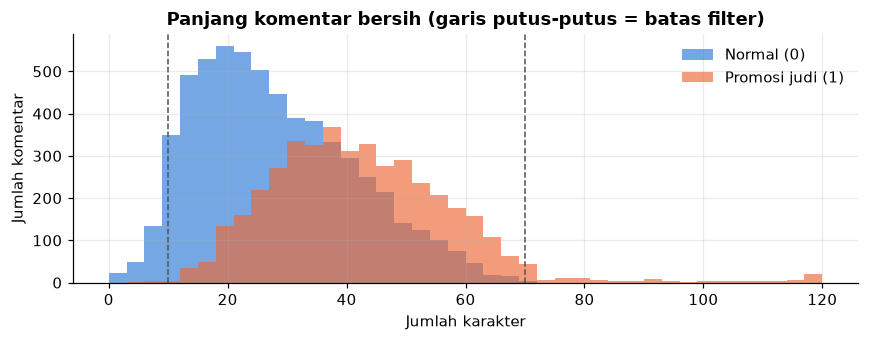

,Kurang dari 10 karakter,Lebih dari 70 karakter
Label,,
Normal (0),269,0
Promosi judi (1),6,106


Sisa: 9,849 baris


In [8]:
MIN_KARAKTER, MAX_KARAKTER = 10, 70

fig, ax = plt.subplots(figsize=(8, 3.2))
for lab in (0, 1):
    ax.hist(df.loc[df["label"] == lab, "panjang"].clip(upper=120), bins=40, range=(0, 120), alpha=0.65,
            color=WARNA_LABEL[lab], label=NAMA_LABEL[lab])
for batas in (MIN_KARAKTER, MAX_KARAKTER):
    ax.axvline(batas, color="#52514e", linestyle="--", linewidth=1)
ax.set(title="Panjang komentar bersih (garis putus-putus = batas filter)", xlabel="Jumlah karakter", ylabel="Jumlah komentar")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("outputs/distribusi_panjang.png", bbox_inches="tight")
plt.show()

terbuang = pd.DataFrame({
    f"Kurang dari {MIN_KARAKTER} karakter": df.loc[df["panjang"] < MIN_KARAKTER, "label"].value_counts(),
    f"Lebih dari {MAX_KARAKTER} karakter": df.loc[df["panjang"] > MAX_KARAKTER, "label"].value_counts(),
}).reindex([0, 1]).fillna(0).astype(int).rename(index=NAMA_LABEL).rename_axis("Label")
tampil(terbuang, "Tabel 1.5. Komentar yang terbuang oleh filter panjang")

df = df[df["panjang"].between(MIN_KARAKTER, MAX_KARAKTER)].copy()
tahapan["Filter panjang"] = df["label"].value_counts()
print(f"Sisa: {len(df):,} baris")

**Perhatikan Tabel 1.5:** semua komentar yang lebih panjang dari 70 karakter berlabel promosi judi. Artinya filter ini
juga membuang promosi yang panjang, dan komentar seperti itu tidak akan dinilai model di notebook 03.

## 6. Membuang konflik label dan duplikat

Komentar spam sering berulang, sehingga teks yang sama cukup disimpan **satu kali**. Tanpa langkah ini, kalimat yang sama
bisa masuk ke data latih sekaligus data uji di notebook 02 dan membuat nilai evaluasi terlalu tinggi.

Sebelum itu, teks yang sama tetapi memiliki **label berbeda** dibuang lebih dulu, karena tidak diketahui label mana yang benar.

In [9]:
konflik = df.groupby("komentar_clean")["label"].transform("nunique") > 1
print(f"Konflik label: {df.loc[konflik, 'komentar_clean'].nunique()} teks unik ({konflik.sum()} baris)")
tampil(df.loc[konflik, ["komentar_clean", "label"]].sort_values(["komentar_clean", "label"]).head(6),
       "Tabel 1.6. Contoh teks yang sama dengan label berbeda", sembunyikan_index=True)
df = df[~konflik]
tahapan["Buang konflik label"] = df["label"].value_counts()

df = df.drop_duplicates(subset="komentar_clean", keep="first")
tahapan["Buang duplikat"] = df["label"].value_counts()
print(f"Sisa: {len(df):,} baris")

Konflik label: 7 teks unik (15 baris)


komentar_clean,label
belik cilok alfa 5k,0
belik cilok alfa 5k,1
bused mewah banget,0
bused mewah banget,1
"dibeliin papi ku singapura , main pubg",0
"dibeliin papi ku singapura , main pubg",1


Sisa: 8,270 baris


## 7. Ringkasan tahapan

**Gambar 1.2. Jumlah komentar per tahap**

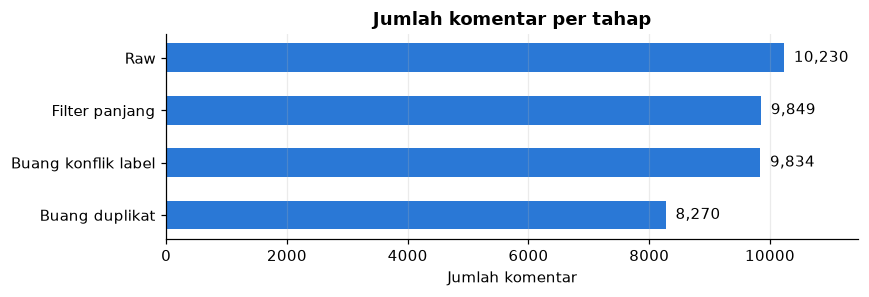

label,Normal (0),Promosi judi (1),Total
Tahap,,,
Raw,6021,4209,10230
Filter panjang,5752,4097,9849
Buang konflik label,5745,4089,9834
Buang duplikat,5720,2550,8270


In [10]:
ringkasan = pd.DataFrame(tahapan).T.fillna(0).astype(int).rename(columns=NAMA_LABEL)
ringkasan["Total"] = ringkasan.sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(ringkasan.index[::-1], ringkasan["Total"][::-1], color=WARNA_LABEL[0], height=0.55)
for i, v in enumerate(ringkasan["Total"][::-1]):
    ax.text(v, i, f"  {v:,}", va="center")
ax.set_xlim(0, ringkasan["Total"].max() * 1.12)
ax.set(title="Jumlah komentar per tahap", xlabel="Jumlah komentar")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("outputs/tahapan_data.png", bbox_inches="tight")
plt.show()

tampil(ringkasan.rename_axis("Tahap"), "Tabel 1.7. Jumlah komentar per tahap dan label", "ringkasan_tahapan.csv")

## 8. Menyimpan CSV clean

Kolom dan urutannya sama dengan dataset raw. Perbedaannya hanya isi `komentar_clean` dan baris yang tersisa.

In [11]:
df_clean = df[df_raw.columns]
df_clean.to_csv("data/dataset_clean.csv", index=False)

cek = pd.read_csv("data/dataset_clean.csv")
assert list(cek.columns) == list(df_raw.columns)
assert cek["komentar_clean"].notna().all() and cek["komentar_clean"].is_unique
print(f"Tersimpan: data/dataset_clean.csv ({len(cek):,} baris, {cek.shape[1]} kolom)")

Tersimpan: data/dataset_clean.csv (8,270 baris, 9 kolom)
